In [179]:
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np

root = '/Users/dsong/Library/CloudStorage/OneDrive-UniversityofIllinois-Urbana/Club/LRI/HAL-1 Data Analysis/'
accel = pd.read_csv(root + 'data/19-06-2026-00-44-18-0xB0-0-Accelerometer.csv')
alt = pd.read_csv(root + 'data/19-06-2026-00-44-18-0x97-0-Barometric Altitude.csv')
gyro = pd.read_csv(root + 'data/19-06-2026-00-44-18-0xB1-0-Primary Gyroscope.csv')
telemega = pd.read_csv(root + 'data/telemega.csv')

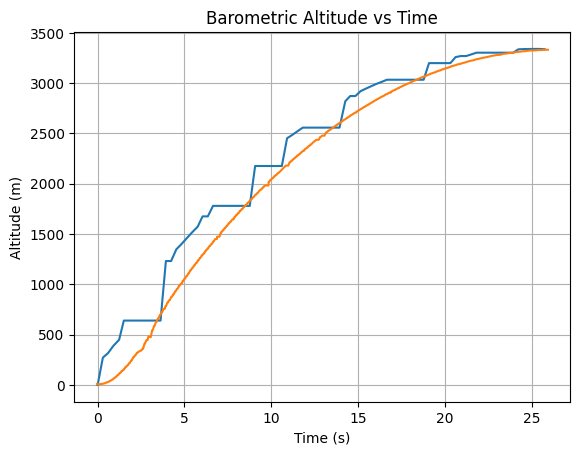

Apogee Altitude: 3342.20 m


In [180]:
alt_t = alt['relseconds'].to_numpy()
alt_t = alt_t - alt_t[0]
altitude = alt['data'].to_numpy()

launch_idx1 = np.argmax(altitude > 0.0) - 1
launch_time = alt_t[launch_idx1]
apogee_idx = np.argmax(altitude)

telemega_time = telemega['time']
telemega_altitude = telemega['altitude']
telemega_speed = telemega['speed']

telemega_altitude = telemega_altitude - telemega_altitude[0]
launch_idx2 = np.argmax(telemega_speed > 1.0)
apogee = telemega_altitude.idxmax()

plt.figure()
plt.plot(alt_t[launch_idx1:apogee_idx] - alt_t[launch_idx1], altitude[launch_idx1:apogee_idx])
plt.plot(telemega_time[launch_idx2:apogee], telemega_altitude[launch_idx2:apogee])
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Barometric Altitude vs Time')
plt.grid(True)
plt.show()

print(f"Apogee Altitude: {altitude[apogee_idx]:.2f} m")

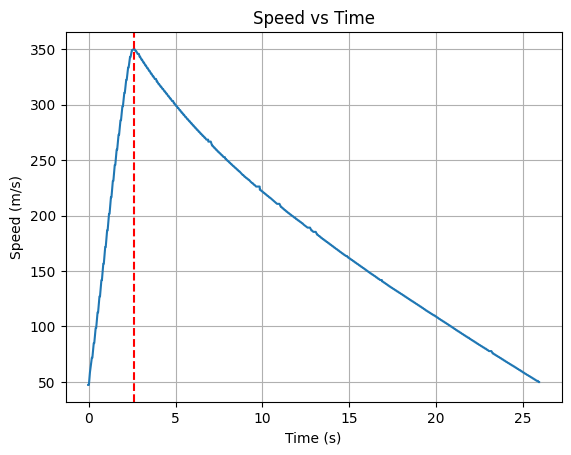

Motor burnout time: 2.59 s


In [181]:
telemega_time = telemega['time']
telemega_speed = telemega['speed']

motor_burnout_idx = np.argmax(telemega_speed)
motor_burnout_time = telemega_time[motor_burnout_idx]

plt.figure()
plt.plot(telemega_time[launch_idx2:apogee], telemega_speed[launch_idx2:apogee])
plt.axvline(x=telemega_time[motor_burnout_idx], color='r', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Speed (m/s)')
plt.title('Speed vs Time')
plt.grid(True)
plt.show()

print(f"Motor burnout time: {motor_burnout_time} s")

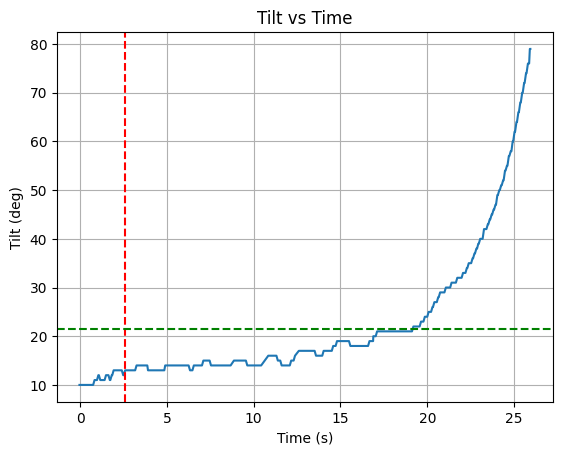

In [182]:
telemega_time = telemega['time']
telemega_tilt = telemega['tilt']
tilt_lockout = np.argmax(telemega_tilt > 30.0)

plt.figure()
plt.plot(telemega_time[launch_idx2:apogee], telemega_tilt[launch_idx2:apogee])
plt.axvline(x=telemega_time[motor_burnout_idx], color='r', linestyle='--')
plt.axhline(y=telemega_time[tilt_lockout], color='g', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Tilt (deg)')
plt.title('Tilt vs Time')
plt.grid(True)
plt.show()

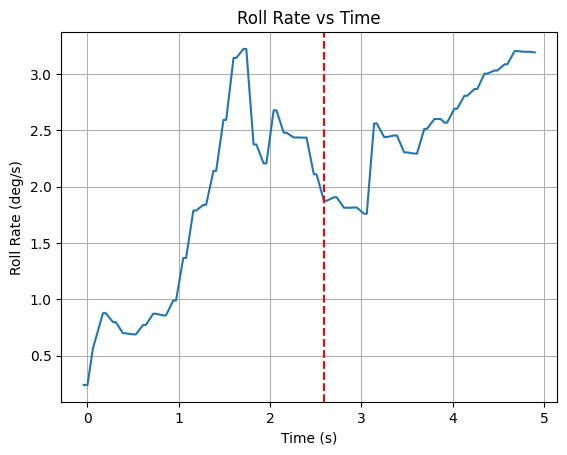

Apogee Altitude: 3342.20 m


In [183]:
gyro_t = gyro['relseconds'].to_numpy()
gyro_t = gyro_t - gyro_t[0]
gyro_x = gyro['x'].to_numpy()
gyro_y = gyro['y'].to_numpy()
gyro_z = gyro['z'].to_numpy()

telemega_time = telemega['time']
telemega_roll = telemega['gyro_roll']
apogee = launch_idx2 + 100
plt.figure()
# plt.plot(alt_t[launch_idx1:apogee_idx] - alt_t[launch_idx1], np.deg2rad(gyro_z[launch_idx1:apogee_idx]))
plt.plot(telemega_time[launch_idx2:apogee], np.deg2rad(telemega_roll[launch_idx2:apogee]))
plt.axvline(x=telemega_time[motor_burnout_idx], color='r', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Roll Rate (deg/s)')
plt.title('Roll Rate vs Time')
plt.grid(True)
plt.show()

print(f"Apogee Altitude: {altitude[apogee_idx]:.2f} m")

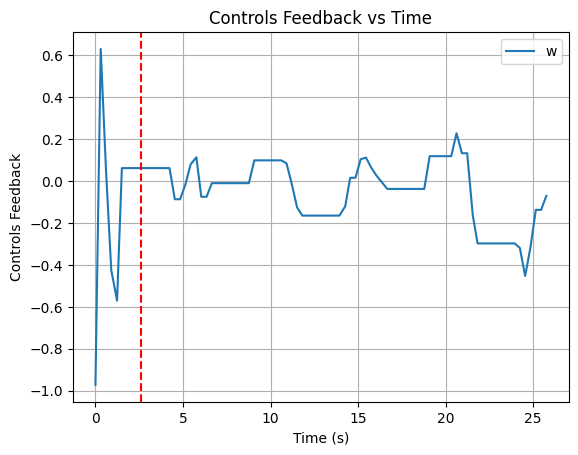

In [184]:
ctrls_feedback = pd.read_csv(root + 'data/19-06-2026-00-44-18-0xC1-0-Controls Feedback.csv')
ctrls_feedback_t = ctrls_feedback['relseconds'].to_numpy()
ctrls_feedback_t = ctrls_feedback_t - ctrls_feedback_t[0]
ctrls_feedback_w = ctrls_feedback['w'].to_numpy()
ctrls_feedback_x = ctrls_feedback['x'].to_numpy()
ctrls_feedback_y = ctrls_feedback['y'].to_numpy()
ctrls_feedback_z = ctrls_feedback['z'].to_numpy()

plt.figure()
plt.plot(ctrls_feedback_t[launch_idx1:apogee_idx]-ctrls_feedback_t[launch_idx1], ctrls_feedback_w[launch_idx1:apogee_idx], label='w')
plt.axvline(x=telemega_time[motor_burnout_idx], color='r', linestyle='--')
# plt.plot(ctrls_feedback_t, ctrls_feedback_x, label='x')
# plt.plot(ctrls_feedback_t, ctrls_feedback_y, label='y')
# plt.plot(ctrls_feedback_t, ctrls_feedback_z, label='z')

plt.xlabel('Time (s)')
plt.ylabel('Controls Feedback')
plt.title('Controls Feedback vs Time')
plt.legend()
plt.grid(True)
plt.show()

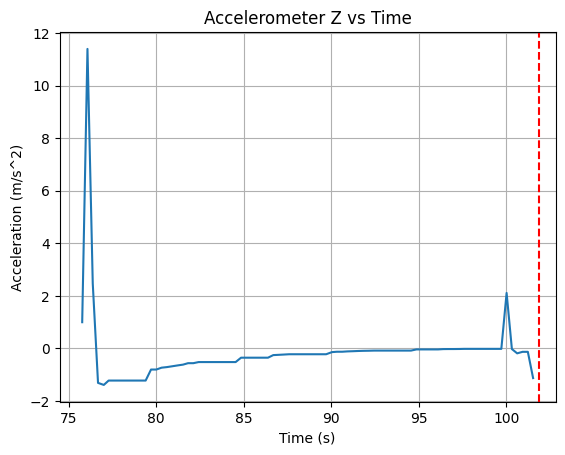

In [185]:
# Accelerometer Z vs Time
accel_t = accel['relseconds'].to_numpy()
accel_t = accel_t - accel_t[0]
accel_x = accel['x'].to_numpy()
accel_y = accel['y'].to_numpy()
accel_z = accel['z'].to_numpy()

plt.figure()
plt.plot(accel_t[launch_idx1:apogee_idx], accel_z[launch_idx1:apogee_idx])
plt.axvline(x=alt_t[apogee_idx], color='r', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.title('Accelerometer Z vs Time')
plt.grid(True)
plt.show()

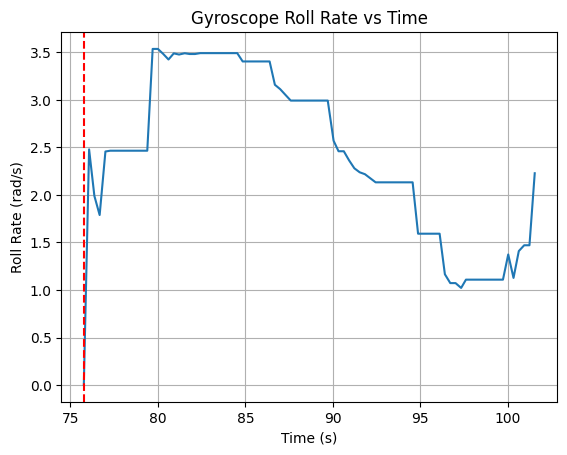

In [186]:
gyro = pd.read_csv(root + 'data/19-06-2026-00-44-18-0xB1-0-Primary Gyroscope.csv')
gyro_t = gyro['relseconds'].to_numpy()
gyro_t = gyro_t - gyro_t[0]
gyro_x = gyro['x'].to_numpy()
gyro_y = gyro['y'].to_numpy()
gyro_z = gyro['z'].to_numpy()
plt.figure()
# plt.plot(gyro_t[240:285], np.deg2rad(gyro_z)[240:285])
plt.plot(gyro_t[launch_idx1:apogee_idx], np.deg2rad(gyro_z)[launch_idx1:apogee_idx])
plt.axvline(x=launch_time, color='r', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Roll Rate (rad/s)')
plt.title('Gyroscope Roll Rate vs Time')
plt.grid(True)
plt.show()


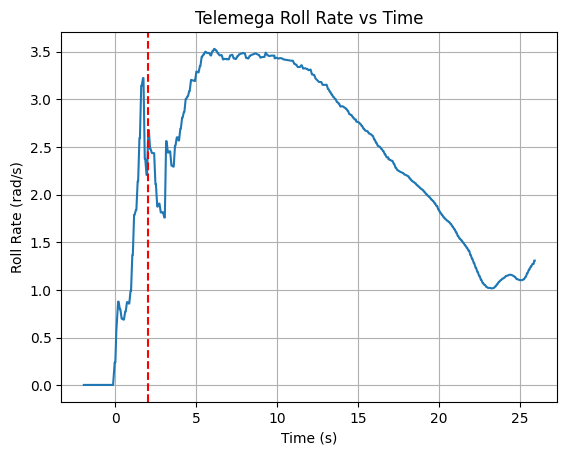

In [187]:
telemega_roll = telemega['gyro_roll']
telemega_altitude = telemega['altitude']
telemega_speed = telemega['speed']
telemega_accel_x = telemega['accel_x']
telemega_time = telemega['time']

apogee = telemega_altitude.idxmax()

plt.figure()
plt.plot(telemega_time[:apogee], np.deg2rad(telemega_roll[:apogee]))
plt.xlabel('Time (s)')
plt.ylabel('Roll Rate (rad/s)')
plt.title('Telemega Roll Rate vs Time')
plt.grid(True)
# plt.plot(telemega_time[:apogee], telemega_speed[:apogee])
plt.axvline(x=2.0, color='r', linestyle='--')
plt.show()

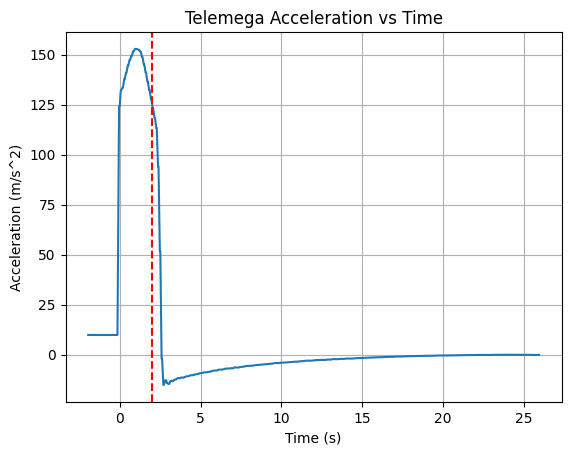

In [188]:
plt.figure()
plt.plot(telemega_time[:apogee], telemega_accel_x[:apogee])
plt.axvline(x=2.0, color='r', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.title('Telemega Acceleration vs Time')
plt.grid(True)
plt.show()

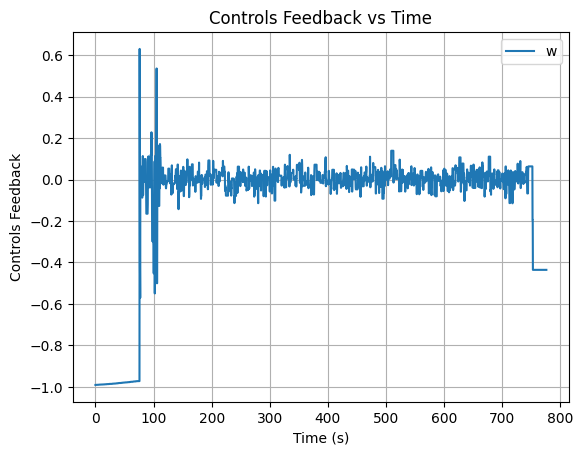

In [189]:
ctrls_feedback = pd.read_csv(root + 'data/19-06-2026-00-44-18-0xC1-0-Controls Feedback.csv')
ctrls_feedback_t = ctrls_feedback['relseconds'].to_numpy()
ctrls_feedback_t = ctrls_feedback_t - ctrls_feedback_t[0]
ctrls_feedback_w = ctrls_feedback['w'].to_numpy()
ctrls_feedback_x = ctrls_feedback['x'].to_numpy()
ctrls_feedback_y = ctrls_feedback['y'].to_numpy()
ctrls_feedback_z = ctrls_feedback['z'].to_numpy()

plt.figure()
plt.plot(ctrls_feedback_t, ctrls_feedback_w, label='w')
# plt.plot(ctrls_feedback_t, ctrls_feedback_x, label='x')
# plt.plot(ctrls_feedback_t, ctrls_feedback_y, label='y')
# plt.plot(ctrls_feedback_t, ctrls_feedback_z, label='z')
plt.xlabel('Time (s)')
plt.ylabel('Controls Feedback')
plt.title('Controls Feedback vs Time')
plt.legend()
plt.grid(True)
plt.show()